# Explore the dev sessions

Step 8 of the Build Plan. Per session: the real raw rate and the gaps, slip angle
over time with the onsets marked, zooms on 3 onsets, a histogram of |slip|, and the
countersteer sign check that sets `COUNTERSTEER_SIGN`. The last section lists every
spin and the commands for the video spot-check (`python -m spinwarn.spotcheck`).

Sessions come from `dev_sessions()` and `load_session`, the cache the pipeline uses,
so the locked test sessions never load here.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from driftscore import logcheck
from spinwarn import config, labeling
from spinwarn.data import dev_sessions, load_raw, load_session
from spinwarn.labeling import find_onsets
from spinwarn.spotcheck import pick, spins

%matplotlib inline
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

SESSIONS = dev_sessions()   # never the locked test sessions
raw = {s: load_raw(config.RAW_DIR / f"{s}.csv") for s in SESSIONS}   # (logger rows, JSON)
grid = {s: load_session(s) for s in SESSIONS}                        # the 60 Hz grid with signals
spinning = {s: find_onsets(grid[s])[1] for s in SESSIONS}
spin_table = {s: spins(grid[s]) for s in SESSIONS}                   # spin, t, peak_slip, speed_kmh
kind = {s: (raw[s][1] or {}).get("kind", "?") for s in SESSIONS}
print(f"{len(SESSIONS)} dev sessions: {', '.join(SESSIONS)}")

3 dev sessions: 2026-10-11_194646, 2026-10-11_200553, 2026-10-11_202102


## Raw rate and gaps

AC's physics rate is packetId change over time; rows/s is what the 1 ms poll kept.
The gaps are every interval over `GAP_S` and every break the JSON lists, labelled
as `logcheck` labels them. A gap over `GAP_S` ends a segment on the grid.

In [2]:
rates, gaps, segments = [], [], []
for s in SESSIONS:
    rows, meta = raw[s]
    t, ids = rows["t"].tolist(), rows["packet_id"].tolist()
    intervals = ((meta or {}).get("summary") or {}).get("break_intervals")
    stats = logcheck.step_stats(t, ids, logcheck.break_rows(t, intervals))
    rates.append({
        "session": s, "kind": kind[s], "rows": len(t),
        "rows/s": stats["rows_per_s"], "AC packets/s": stats["packet_rate"],
        "steps of 2+ (%)": 100 * stats["skip_share"],
        "grid frames": len(grid[s]), "grid min": len(grid[s]) / config.GRID_HZ / 60,
    })
    for g in logcheck.find_gaps(t, ids, stats["packet_rate"], intervals):
        gaps.append({
            "session": s, "from (s)": g["start_s"], "to (s)": g["end_s"],
            "length (s)": g["end_s"] - g["start_s"], "packetId step": g["step"],
            "label": g["label"], "note": g["note"],
        })
    for segment, frames in grid[s].groupby("segment")["t"]:
        segments.append({"session": s, "segment": segment, "from (s)": frames.iloc[0],
                         "to (s)": frames.iloc[-1], "frames": len(frames)})

display(pd.DataFrame(rates).set_index("session").round(2))
display(pd.DataFrame(gaps).set_index("session").round(3))
display(pd.DataFrame(segments).set_index("session").round(2))

,kind,rows,rows/s,AC packets/s,steps of 2+ (%),grid frames,grid min
session,,,,,,,
2026-10-11_194646,natural,289837,333.27,333.63,0.02,52180,14.49
2026-10-11_200553,deliberate,164324,333.29,333.33,0.01,29583,8.22
2026-10-11_202102,natural,199594,333.25,333.33,0.01,35937,9.98


,from (s),to (s),length (s),packetId step,label,note
session,,,,,,
2026-10-11_194646,551.871,552.553,0.681,1,PAUSE,
2026-10-11_194646,552.553,552.666,0.114,8,pause,"the JSON says AC was live, but packetId moved ..."
2026-10-11_194646,869.658,872.631,2.973,1,PAUSE,
2026-10-11_200553,1.162,1.178,0.016,5,PAUSE,
2026-10-11_202102,0.870,0.887,0.018,1,PAUSE,


,segment,from (s),to (s),frames
session,,,,
2026-10-11_194646,0,0.12,551.87,33106
2026-10-11_194646,2,552.67,869.65,19020
2026-10-11_194646,3,872.63,873.52,54
2026-10-11_200553,0,1.17,494.20,29583
2026-10-11_202102,0,0.88,599.82,35937


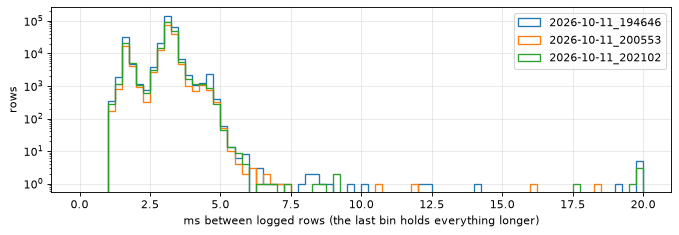

In [3]:
# Row-to-row intervals: AC's ~3 ms physics step, and how rare anything longer is.
bins = np.arange(0, 20.25, 0.25)
fig, ax = plt.subplots(figsize=(10, 3))
for s in SESSIONS:
    dt_ms = np.diff(raw[s][0]["t"].to_numpy()) * 1000
    ax.hist(np.clip(dt_ms, None, bins[-1]), bins=bins, histtype="step", lw=1.2, label=s)
ax.set(yscale="log", xlabel="ms between logged rows (the last bin holds everything longer)", ylabel="rows")
ax.legend()
plt.show()

## Slip angle over time, onsets marked

Signed slip angle, with each onset the label rule finds (numbered, as in the tables
below) and its spin shaded from onset to re-arm. Dotted lines at ±`SPIN_DEG`.

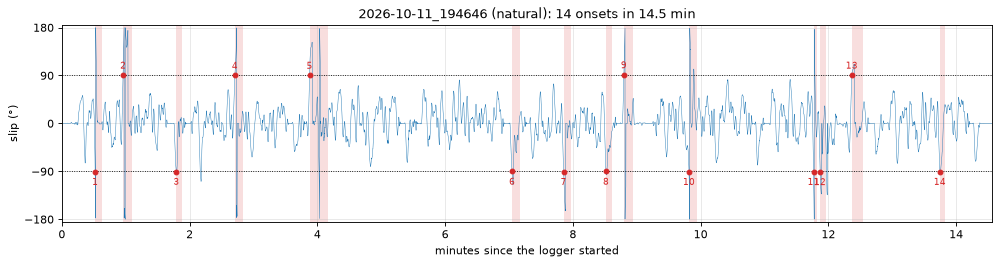

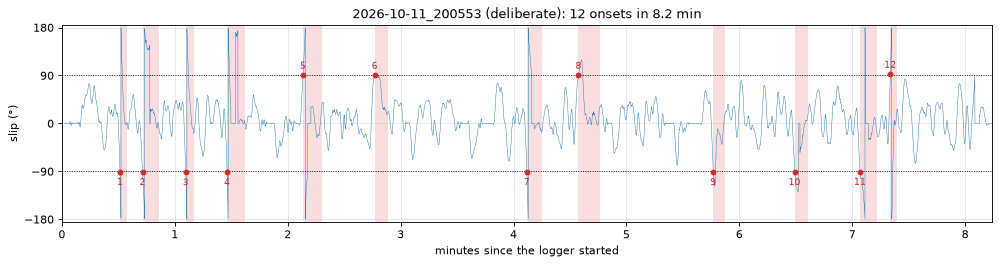

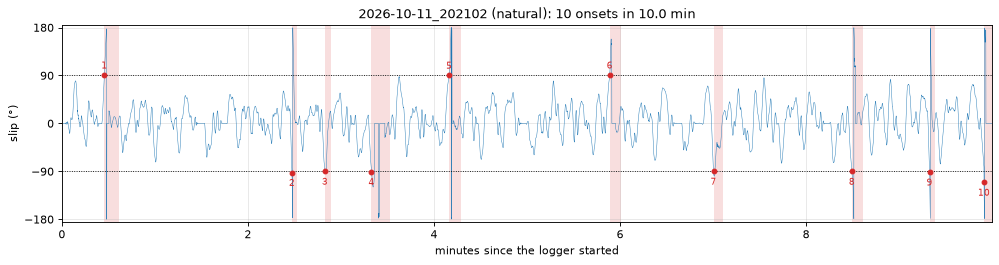

In [4]:
def runs(mask):
    """(first, last) row of each run of True in mask."""
    edges = np.diff(np.concatenate([[0], mask.astype(int), [0]]))
    return zip(np.flatnonzero(edges == 1), np.flatnonzero(edges == -1) - 1)


for s in SESSIONS:
    g, table = grid[s], spin_table[s]
    t, slip = g["t"].to_numpy(), g["slip_deg"].to_numpy()
    minutes = t / 60
    fig, ax = plt.subplots(figsize=(15, 3.2))
    ax.plot(minutes, slip, lw=0.4)
    for first, last in runs(spinning[s]):
        ax.axvspan(minutes[first], minutes[last], color="tab:red", alpha=0.15, lw=0)
    onset = np.searchsorted(t, table["t"])
    ax.scatter(minutes[onset], slip[onset], color="tab:red", zorder=3, s=18)
    for spin, x, y in zip(table["spin"], minutes[onset], slip[onset]):
        ax.annotate(str(spin), (x, y), xytext=(0, 6 if y > 0 else -12), textcoords="offset points",
                    ha="center", fontsize=8, color="tab:red")
    for y in (-config.SPIN_DEG, config.SPIN_DEG):
        ax.axhline(y, color="k", ls=":", lw=0.8)
    ax.set(xlim=(0, minutes[-1]), ylim=(-185, 185), yticks=range(-180, 181, 90),
           xlabel="minutes since the logger started", ylabel="slip (°)",
           title=f"{s} ({kind[s]}): {len(table)} onsets in {len(g) / config.GRID_HZ / 60:.1f} min")
    plt.show()

## Zooms on 3 onsets

Three onsets per session, picked with `SEED` the way `spotcheck` picks them, from
3 s before the onset to 1.5 s after. The red line is the onset; the shaded band is
the `HORIZON_S` before it, the frames labelled positive.

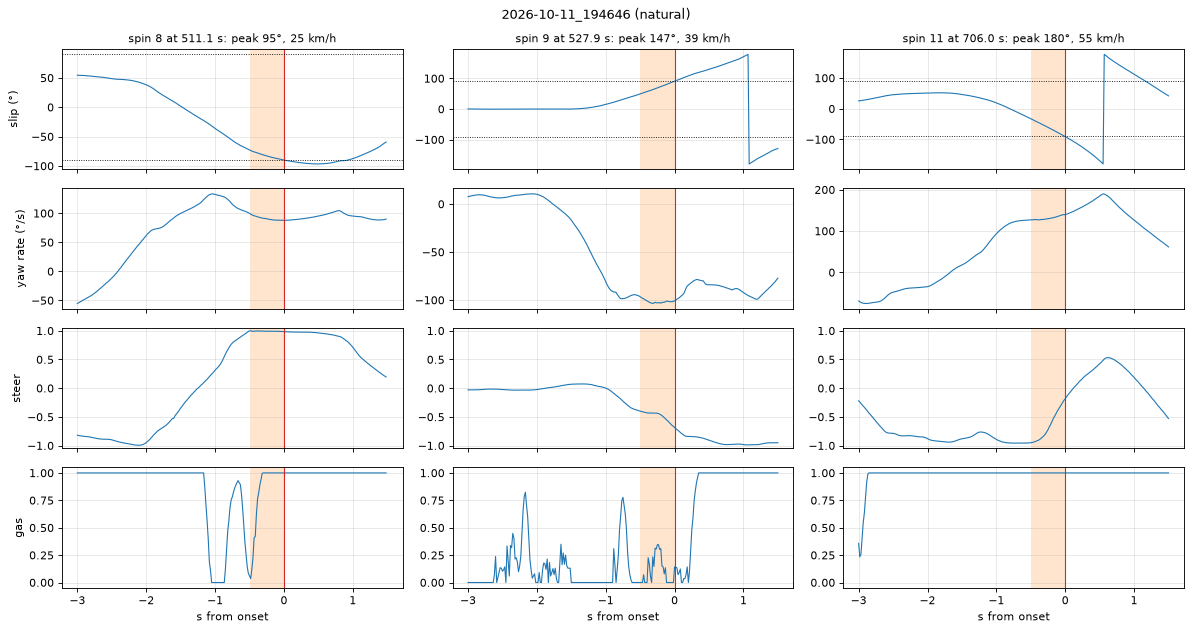

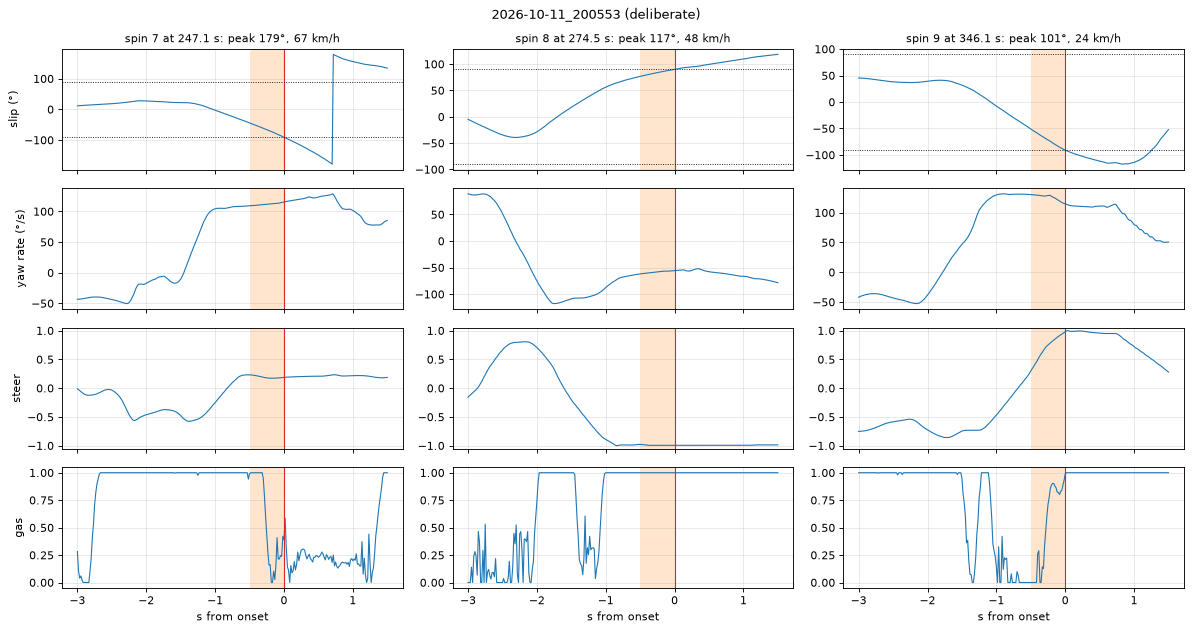

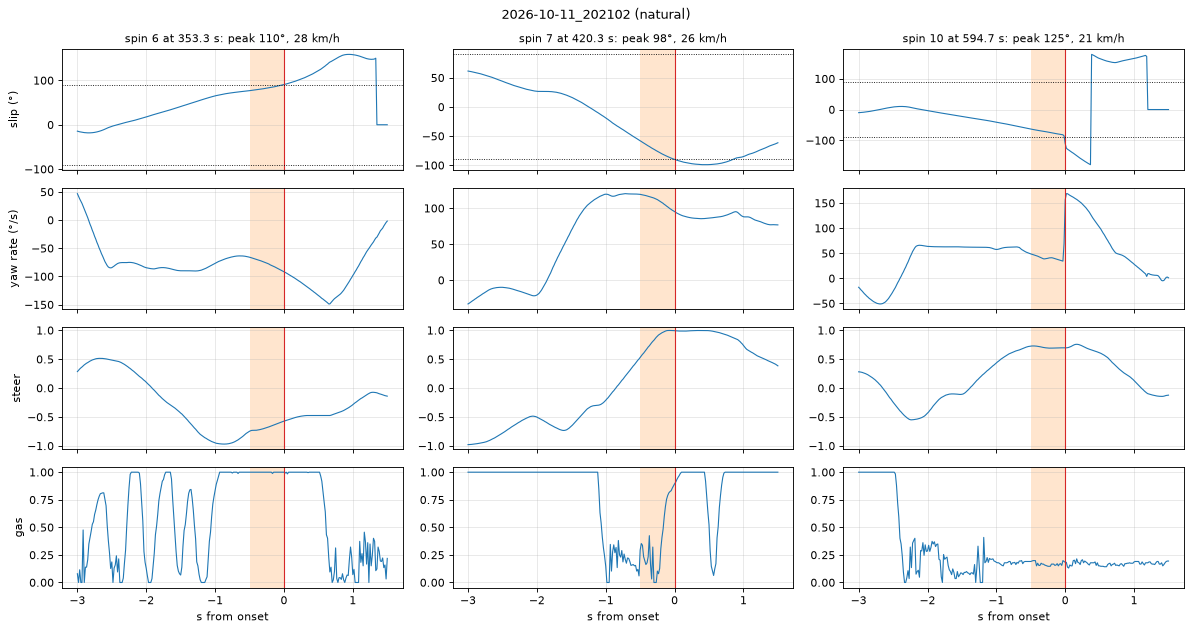

In [5]:
BEFORE_S, AFTER_S = 3.0, 1.5
SIGNALS = [("slip_deg", "slip (°)"), ("yaw_rate", "yaw rate (°/s)"), ("steer", "steer"), ("gas", "gas")]
LIMITS = {"steer": (-1.05, 1.05), "gas": (-0.05, 1.05)}

for s in SESSIONS:
    g = grid[s]
    chosen = pick(spin_table[s], 3)
    fig, axes = plt.subplots(len(SIGNALS), len(chosen), figsize=(15, 8), sharex=True, squeeze=False)
    for j, spin in enumerate(chosen.itertuples()):
        near = g[g["t"].between(spin.t - BEFORE_S, spin.t + AFTER_S)]
        x = near["t"] - spin.t
        for i, (column, name) in enumerate(SIGNALS):
            ax = axes[i, j]
            ax.plot(x, near[column], lw=1)
            ax.axvline(0, color="tab:red", lw=1)
            ax.axvspan(-config.HORIZON_S, 0, color="tab:orange", alpha=0.2, lw=0)
            if column == "slip_deg":
                for y in (-config.SPIN_DEG, config.SPIN_DEG):
                    ax.axhline(y, color="k", ls=":", lw=0.8)
            if column in LIMITS:
                ax.set_ylim(*LIMITS[column])
            if j == 0:
                ax.set_ylabel(name)
        axes[0, j].set_title(f"spin {spin.spin} at {spin.t:.1f} s: peak {spin.peak_slip:.0f}°, "
                             f"{spin.speed_kmh:.0f} km/h", fontsize=10)
        axes[-1, j].set_xlabel("s from onset")
    fig.suptitle(f"{s} ({kind[s]})")
    fig.tight_layout()
    plt.show()

## Where the drifts sit: a histogram of |slip|

Every frame at `MIN_SPEED_KMH` or more, split into spinning (onset to re-arm) and
not, on a log scale so the tail toward 90° shows. The not-spinning frames are the drifting and driving the model has to tell
apart from what comes before a spin; the closer they sit to 90°, the more an
intended high angle could trip the rule. Dotted lines at `REARM_DEG` and `SPIN_DEG`.

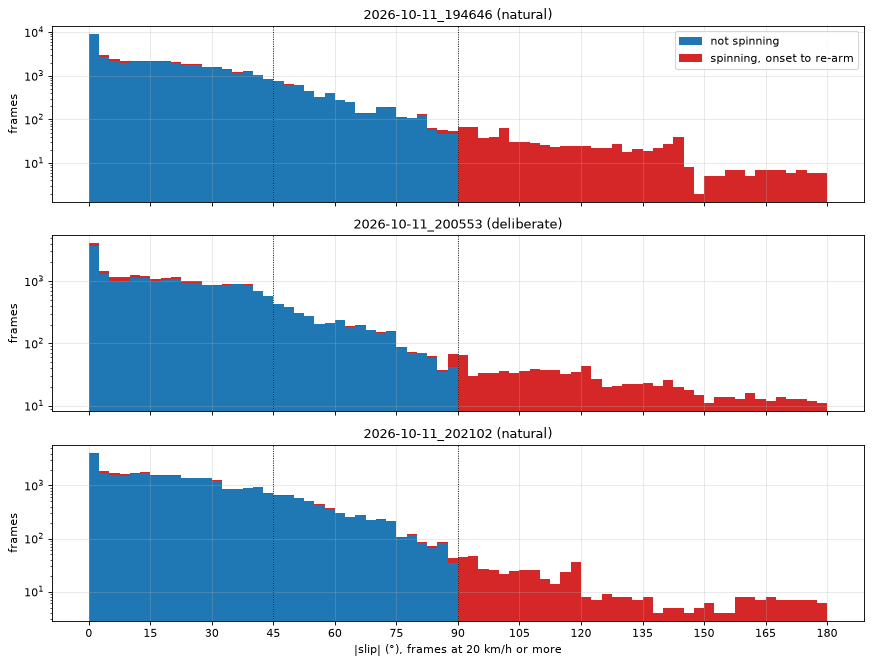

|slip| of the not-spinning frames at speed:


,median,90th pct,99th pct,over 45° (%),over 60° (%),over 75° (%),over 85° (%)
session,,,,,,,
2026-10-11_194646,17.0,46.7,76.4,11.2,3.8,1.1,0.2
2026-10-11_200553,20.6,50.9,78.9,14.0,6.2,1.6,0.3
2026-10-11_202102,21.0,53.3,79.2,16.4,6.3,1.5,0.4


In [6]:
bins = np.arange(0, 182.5, 2.5)
fig, axes = plt.subplots(len(SESSIONS), 1, figsize=(11, 2.8 * len(SESSIONS)), sharex=True, squeeze=False)
shares = []
for ax, s in zip(axes[:, 0], SESSIONS):
    g = grid[s]
    fast = g["speed_kmh"].to_numpy() >= config.MIN_SPEED_KMH
    slip = g["abs_slip"].to_numpy()
    held, spun = slip[fast & ~spinning[s]], slip[fast & spinning[s]]
    ax.hist([held, spun], bins=bins, stacked=True, color=["tab:blue", "tab:red"],
            label=["not spinning", "spinning, onset to re-arm"])
    for x in (config.REARM_DEG, config.SPIN_DEG):
        ax.axvline(x, color="k", ls=":", lw=0.8)
    ax.set(yscale="log", ylabel="frames", title=f"{s} ({kind[s]})")
    shares.append({
        "session": s, "median": np.median(held),
        "90th pct": np.percentile(held, 90), "99th pct": np.percentile(held, 99),
        **{f"over {d}° (%)": 100 * (held > d).mean() for d in (45, 60, 75, 85)},
    })
axes[0, 0].legend()
axes[-1, 0].set(xlabel="|slip| (°), frames at 20 km/h or more", xticks=range(0, 181, 15))
fig.tight_layout()
plt.show()
print("|slip| of the not-spinning frames at speed:")
display(pd.DataFrame(shares).set_index("session").round(1))

## Countersteer sign

`countersteer = steer × sign(slip) × COUNTERSTEER_SIGN`, and held drifts should read
positive: steering into the slide. Held drifts here are frames with |slip| 20–70°,
over 30 km/h and not spinning, as in Step 6's check. The product below is before
`COUNTERSTEER_SIGN`, so it shows which sign config.py needs.

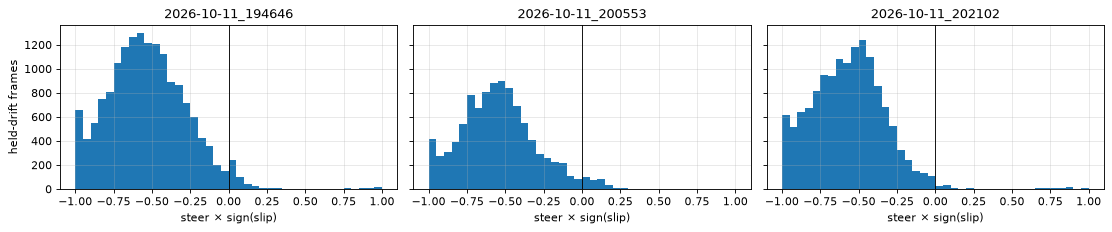

,held-drift frames,negative (%),median,countersteer median
session,,,,
2026-10-11_194646,16208,97.00,-0.55,0.55
2026-10-11_200553,9956,96.73,-0.56,0.56
2026-10-11_202102,13959,98.98,-0.56,0.56


Held drifts read negative before the sign: COUNTERSTEER_SIGN should be -1.
config.py has -1: matches.


In [7]:
HELD_SLIP_DEG, HELD_SPEED_KMH = (20, 70), 30   # held drifts, for this check only

fig, axes = plt.subplots(1, len(SESSIONS), figsize=(14, 3), sharey=True, squeeze=False)
checks, products = [], []
for ax, s in zip(axes[0], SESSIONS):
    g = grid[s]
    held = (g["abs_slip"].between(*HELD_SLIP_DEG) & (g["speed_kmh"] > HELD_SPEED_KMH)).to_numpy() & ~spinning[s]
    product = (g["steer"] * np.sign(g["slip_deg"])).to_numpy()[held]
    products.append(product)
    ax.hist(product, bins=np.linspace(-1, 1, 41))
    ax.axvline(0, color="k", lw=0.8)
    ax.set(title=s, xlabel="steer × sign(slip)")
    checks.append({
        "session": s, "held-drift frames": held.sum(), "negative (%)": 100 * (product < 0).mean(),
        "median": np.median(product), "countersteer median": np.median(g["countersteer"].to_numpy()[held]),
    })
axes[0, 0].set_ylabel("held-drift frames")
fig.tight_layout()
plt.show()
display(pd.DataFrame(checks).set_index("session").round(2))

sign = -1 if np.median(np.concatenate(products)) < 0 else 1
print(f"Held drifts read {'negative' if sign < 0 else 'positive'} before the sign: COUNTERSTEER_SIGN should be {sign}.")
print(f"config.py has {config.COUNTERSTEER_SIGN}: " + ("matches." if config.COUNTERSTEER_SIGN == sign else "change it."))

## Every spin, and the spot-check

Each spin with its peak |slip| at speed (as `spotcheck` prints it), how long it
stays over `SPIN_DEG` from the onset at `MIN_SPEED_KMH` or more and out of reverse
(what `SPIN_HOLD_S` holds for), and the lowest speed before re-arm. A spin that ends
at a crawl is a real spin; a short stay over 90° is the kind of intended high angle
`SPIN_HOLD_S = 0.25` would drop.

In [8]:
details = []
for s in SESSIONS:
    g = grid[s]
    t, slip, speed = g["t"].to_numpy(), g["abs_slip"].to_numpy(), g["speed_kmh"].to_numpy()
    # The frames that count toward a spin's hold, as find_onsets has them.
    counts_over = (slip > config.SPIN_DEG) & (speed >= config.MIN_SPEED_KMH) & (g["gear"].to_numpy() != config.REVERSE_GEAR)
    ends = np.append(np.flatnonzero(~spinning[s]), len(g))
    for spin in spin_table[s].itertuples():
        first = np.searchsorted(t, spin.t)
        end = ends[np.searchsorted(ends, first)]
        over = counts_over[first:end]
        details.append({
            "session": s, "spin": spin.spin, "t (s)": spin.t, "peak slip (°)": spin.peak_slip,
            "speed (km/h)": spin.speed_kmh,
            "over 90° at speed (s)": (len(over) if over.all() else over.argmin()) / config.GRID_HZ,
            "lowest speed (km/h)": speed[first:end].min(), "re-armed after (s)": (end - first) / config.GRID_HZ
            if end < len(g) else np.nan,
        })
details = pd.DataFrame(details)
display(details.set_index(["session", "spin"]).round(2))

t (s)  peak slip (°)  speed (km/h)  \
session           spin                                        
2026-10-11_194646 1      31.25         179.89         59.25   
                  2      57.55         143.41         39.86   
                  3     107.53          91.45         22.31   
                  4     162.47         133.61         46.15   
                  5     232.65         147.27         67.21   
                  6     422.85          95.19         23.74   
                  7     471.25         143.28         47.78   
                  8     511.08          95.35         24.96   
                  9     527.85         146.98         39.46   
                  10    589.02         179.83         46.12   
                  11    706.05         179.58         54.76   
                  12    712.10         129.93         45.79   
                  13    741.93         109.54         59.26   
                  14    824.63          95.04         35.11   
2026-10-11_200553 1      30.88         179.18         66.43   
                  2      42.87         140.55         41.10   
                  3      65.83         179.63         53.10   
                  4      87.82         179.01         45.74   
                  5     128.17         174.78         44.32   
                  6     166.23          91.31         36.70   
                  7     247.12         179.31         66.64   
                  8     274.50         117.03         47.93   
                  9     346.12         101.33         24.21   
                  10    389.40         124.00         56.59   
                  11    424.13         147.02         73.26   
                  12    440.23         179.18         94.67   
2026-10-11_202102 1      27.37         137.17         38.28   
                  2     148.40         179.55         53.27   
                  3     169.65          93.69         50.75   
                  4     199.65         119.43         66.09   
                  5     249.82         115.54         31.66   
                  6     353.30         109.59         27.92   
                  7     420.27          98.22         26.47   
                  8     509.50         179.72         74.46   
                  9     559.58         178.41         54.78   
                  10    594.72         125.27         20.67   

                        over 90° at speed (s)  lowest speed (km/h)  \
session           spin                                               
2026-10-11_194646 1                      1.22                13.12   
                  2                      0.63                 0.05   
                  3                      0.15                 7.00   
                  4                      1.17                 0.10   
                  5                      1.67                 0.06   
                  6                      0.23                 5.70   
                  7                      1.00                 0.01   
                  8                      0.32                 8.70   
                  9                      0.75                 0.06   
                  10                     1.05                 1.18   
                  11                     1.17                24.07   
                  12                     0.95                 3.88   
                  13                     1.80                 0.04   
                  14                     0.70                16.66   
2026-10-11_200553 1                      1.23                27.13   
                  2                      0.77                 1.87   
                  3                      1.37                16.44   
                  4                      1.13                 0.09   
                  5                      1.12                 0.18   
                  6                      0.57                 7.30   
                  7                      1.90                 2.12   
                  8 

In [9]:
# What SPIN_HOLD_S = 0.25 would change: the rule rerun with the hold.
saved = labeling.SPIN_HOLD_S
try:
    labeling.SPIN_HOLD_S = 0.25
    with_hold = {s: len(find_onsets(grid[s])[0]) for s in SESSIONS}
finally:
    labeling.SPIN_HOLD_S = saved

rows = []
for s in SESSIONS:
    spun = details[details["session"] == s]
    rows.append({
        "session": s, "kind": kind[s], "min": len(grid[s]) / config.GRID_HZ / 60,
        "onsets": len(spun), "with SPIN_HOLD_S 0.25": with_hold[s],
        "under 0.25 s over 90° at speed": int((spun["over 90° at speed (s)"] < 0.25).sum()),
        "down to 10 km/h or less": int((spun["lowest speed (km/h)"] <= 10).sum()),
    })
total = {k: sum(r[k] for r in rows) for k in rows[0] if k not in ("session", "kind")}
counts = pd.DataFrame(rows + [{"session": "total", "kind": "", **total}]).set_index("session")
counts["per min"] = counts["onsets"] / counts["min"]
display(counts.round(1))

,kind,min,onsets,with SPIN_HOLD_S 0.25,under 0.25 s over 90° at speed,down to 10 km/h or less,per min
session,,,,,,,
2026-10-11_194646,natural,14.5,14,12,2,11,1.0
2026-10-11_200553,deliberate,8.2,12,11,1,9,1.5
2026-10-11_202102,natural,10.0,10,9,1,7,1.0
total,,32.7,36,32,4,27,1.1


The spot-check: 20 onsets in all, split across the sessions in proportion to their
spins. Read each session's video offset off its recording (the video time at which
the logger's status line shows t = 0), run its command, watch each onset and mark
it hit or miss in `notes.md`. Under 18/20, set `SPIN_HOLD_S = 0.25` and rerun.

In [10]:
SPOT_N = 20   # the Project Plan's spot-check size
spun = np.array([len(spin_table[s]) for s in SESSIONS])
share = min(SPOT_N, spun.sum()) * spun / spun.sum()
n = np.floor(share).astype(int)
n[np.argsort(n - share)[: min(SPOT_N, spun.sum()) - n.sum()]] += 1   # largest remainders get the rest
for s, k in zip(SESSIONS, n):
    print(f"python -m spinwarn.spotcheck {s} --n {k} --video-offset <s>")

python -m spinwarn.spotcheck 2026-10-11_194646 --n 8 --video-offset <s>
python -m spinwarn.spotcheck 2026-10-11_200553 --n 7 --video-offset <s>
python -m spinwarn.spotcheck 2026-10-11_202102 --n 5 --video-offset <s>
